In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

In [2]:
conn=sqlite3.connect('../data/checking-logs.sqlite')

In [3]:
df = pd.read_sql("""
    SELECT timestamp
    FROM checker
    WHERE uid LIKE 'user_%'
    """, conn)
df

,timestamp
0,2020-04-17 05:19:02.744528
1,2020-04-17 05:22:35.249331
2,2020-04-17 05:22:45.549397
3,2020-04-17 05:34:14.691200
4,2020-04-17 05:34:24.422370
...,...
3202,2020-05-21 20:19:06.872761
3203,2020-05-21 20:22:41.785725
3204,2020-05-21 20:22:41.877806
3205,2020-05-21 20:37:00.129678


In [4]:
df = pd.read_sql(
    "SELECT * FROM checker WHERE uid LIKE 'user_%'",
    conn
)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.weekday  # Monday=0 … Sunday=6
df["date"] = df["timestamp"].dt.date
df["day_type"] = df["weekday"].apply(
    lambda x: "weekend" if x >= 5 else "working days"
)

df


,index,status,success,timestamp,numTrials,labname,uid,hour,weekday,date,day_type
0,7,ready,0,2020-04-17 05:19:02.744528,1,project1,user_4,5,4,2020-04-17,working days
1,8,checking,0,2020-04-17 05:22:35.249331,2,project1,user_4,5,4,2020-04-17,working days
2,9,ready,1,2020-04-17 05:22:45.549397,2,project1,user_4,5,4,2020-04-17,working days
3,10,checking,1,2020-04-17 05:34:14.691200,3,project1,user_4,5,4,2020-04-17,working days
4,11,ready,1,2020-04-17 05:34:24.422370,3,project1,user_4,5,4,2020-04-17,working days
...,...,...,...,...,...,...,...,...,...,...,...
3202,3397,ready,0,2020-05-21 20:19:06.872761,7,laba06s,user_1,20,3,2020-05-21,working days
3203,3398,checking,0,2020-05-21 20:22:41.785725,8,laba06s,user_1,20,3,2020-05-21,working days
3204,3399,ready,0,2020-05-21 20:22:41.877806,8,laba06s,user_1,20,3,2020-05-21,working days
3205,3400,checking,0,2020-05-21 20:37:00.129678,9,laba06s,user_1,20,3,2020-05-21,working days


In [5]:
conn.close()

In [6]:
df["date"] = df["timestamp"].dt.date
df["weekdays"] = df["timestamp"].dt.weekday
df["day_type"] = df["weekdays"].apply(
    lambda x: "working_day" if x < 5 else "weekend"
)
df["hour"] = df["timestamp"].dt.hour

df = df.sort_values(by=["date", "hour"])

df1 = df[["day_type", "date", "hour"]]

df1


,day_type,date,hour
0,working_day,2020-04-17,5
1,working_day,2020-04-17,5
2,working_day,2020-04-17,5
3,working_day,2020-04-17,5
4,working_day,2020-04-17,5
...,...,...,...
3202,working_day,2020-05-21,20
3203,working_day,2020-05-21,20
3204,working_day,2020-05-21,20
3205,working_day,2020-05-21,20


In [7]:
hourly_daily = (
    df1
    .groupby(["day_type", "hour"])
    .size()
    .reset_index(name="commits")
)

hourly_daily


,day_type,hour,commits
0,weekend,0,6
1,weekend,1,6
2,weekend,3,1
3,weekend,5,2
4,weekend,7,16
5,weekend,8,28
6,weekend,9,22
7,weekend,10,28
8,weekend,11,118
9,weekend,12,57


In [8]:
pivot = hourly_daily.pivot(
    index='hour',
    columns='day_type',
    values='commits')

pivot = pivot.reindex(range(24))
pivot=pivot.fillna(0)
pivot

day_type,weekend,working_day
hour,,
0,6.0,6.0
1,6.0,0.0
2,0.0,0.0
3,1.0,2.0
4,0.0,0.0
5,2.0,15.0
6,0.0,3.0
7,16.0,31.0
8,28.0,37.0


In [9]:
weekends=pivot['weekend'].tolist()
working_days=pivot['working_day'].tolist()
print(weekends)
print(working_days)

[6.0, 6.0, 0.0, 1.0, 0.0, 2.0, 0.0, 16.0, 28.0, 22.0, 28.0, 118.0, 57.0, 108.0, 87.0, 114.0, 74.0, 50.0, 68.0, 105.0, 117.0, 72.0, 59.0, 32.0]
[6.0, 0.0, 0.0, 2.0, 0.0, 15.0, 3.0, 31.0, 37.0, 30.0, 132.0, 88.0, 79.0, 73.0, 122.0, 141.0, 170.0, 192.0, 167.0, 214.0, 183.0, 292.0, 45.0, 15.0]


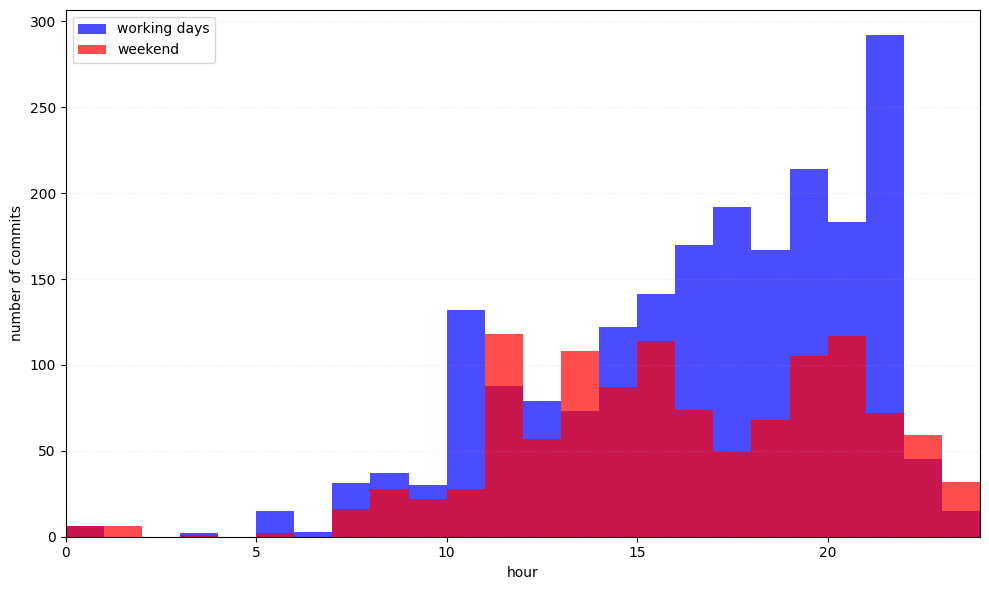

In [10]:
plt.figure(figsize=(10, 6))

plt.stairs(working_days, range(25),
           fill=True, color='blue', label='working days', alpha=0.7)

plt.stairs(weekends, range(25),
           fill=True, color='red', label='weekend', alpha=0.7)

plt.xlim(0, 24)
plt.ylim(0)
plt.xlabel('hour')
plt.ylabel('number of commits')
plt.legend()
plt.xticks(range(0,24, 5))
plt.grid(axis='y', alpha=0.25, ls=':')

plt.tight_layout()
plt.show()

In [11]:
pivot[pivot['weekend']>pivot['working_day']][:4].sort_values('weekend',ascending=False)

day_type,weekend,working_day
hour,,
11,118.0,88.0
13,108.0,73.0
22,59.0,45.0
1,6.0,0.0


Are there hours when the total number of commits was higher on weekends than on working days?

Yes

Examples: 11, 13,22,1
| Hour | Working Days | Weekend |
|------|--------------|---------|
| 1    | 0            | 6       |
| 11   | 88           | 118     |
| 13   | 73           | 108     |
| 22   | 45           | 59      |